# Section 1: ENVIRONMENT SETUP & DATA INGESTION

In [1]:

# CELL : ENVIRONMENT SETUP & DATA INGESTION

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from pathlib import Path

# Machine Learning & Imputation Imports
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.impute import SimpleImputer
from xgboost import XGBClassifier, plot_importance

pd.set_option("display.max_columns", 120)

# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# 2. Navigate to Directory
%cd "/content/drive/MyDrive/GCI_Personal/Final Assignment"

# 3. Define Paths and Validate
current_dir = Path(os.getcwd())
client_path = current_dir / "telecom" / "Client.csv"
record_path = current_dir / "telecom" / "Record.csv"

for p in (client_path, record_path):
    print(f"{'OK ' if p.exists() else 'MISSING '} {p}")

# 4. Load Datasets
client = pd.read_csv(client_path)
record = pd.read_csv(record_path)

print(f"Client shape: {client.shape}")
print(f"Record shape: {record.shape}")

# 5. Merge on Customer_ID (1:1 relation)
df = record.merge(client, on='Customer_ID', how='inner')

# Sort by Customer_ID to guarantee deterministic row ordering for our train/test splits
df = df.sort_values('Customer_ID').reset_index(drop=True)
print(f"Merged & Sorted shape: {df.shape}")

Mounted at /content/drive
/content/drive/MyDrive/GCI_Personal/Final Assignment
OK  /content/drive/MyDrive/GCI_Personal/Final Assignment/telecom/Client.csv
OK  /content/drive/MyDrive/GCI_Personal/Final Assignment/telecom/Record.csv
Client shape: (100000, 50)
Record shape: (100000, 51)
Merged & Sorted shape: (100000, 100)


# Section 2: EXPLORATORY DATA ANALYSIS (SLIDE METRIC PROOFS)

In [2]:

# CELL : EXPLORATORY DATA ANALYSIS (SLIDE METRIC PROOFS)

print("=== VERIFYING SLIDE METRICS (BASELINE CRISIS) ===")
print(f"Total Base Cohort Sample Size: {len(df)}")
print(f"Baseline Churn Structural Breakdown:\n{df['churn'].value_counts(normalize=True) * 100}\n")
print(f"Median Portfolio Total Revenue (totrev): ${df['totrev'].median():.2f}")
print(f"Mean Monthly Account Value (avgrev): ${df['avgrev'].mean():.2f}\n")

print("=== VERIFYING SLIDE METRICS (BEHAVIORAL INSIGHTS) ===")
eda_stats = df.groupby('churn').agg({
    'drop_vce_Mean': 'mean',
    'change_mou': 'mean',
    'eqpdays': 'mean'
})
print("Dropped Calls, MOU Velocity, and Equipment Age Means:")
print(eda_stats, "\n")

print("=== VERIFYING SLIDE  METRICS (PORTFOLIO SEGMENTATION) ===")
seg_stats = df.groupby('churn').agg({
    'totrev': 'median',
    'mou_Mean': 'median',
    'totmrc_Mean': 'median'
})
print("Portfolio Segmentation Grid (Medians):")
print(seg_stats)

=== VERIFYING SLIDE METRICS (BASELINE CRISIS) ===
Total Base Cohort Sample Size: 100000
Baseline Churn Structural Breakdown:
churn
0    50.438
1    49.562
Name: proportion, dtype: float64

Median Portfolio Total Revenue (totrev): $804.53
Mean Monthly Account Value (avgrev): $57.91

=== VERIFYING SLIDE METRICS (BEHAVIORAL INSIGHTS) ===
Dropped Calls, MOU Velocity, and Equipment Age Means:
       drop_vce_Mean  change_mou     eqpdays
churn                                       
0           6.090553   -5.344265  363.280925
1           5.817222  -22.759003  421.089524 

=== VERIFYING SLIDE  METRICS (PORTFOLIO SEGMENTATION) ===
Portfolio Segmentation Grid (Medians):
        totrev  mou_Mean  totmrc_Mean
churn                                
0      784.400    380.50      44.9900
1      823.655    329.75      43.4175


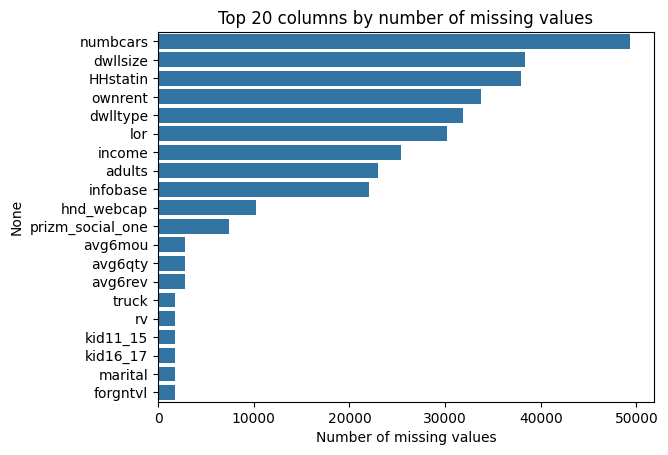

In [3]:
# Count of missing values per column
missing_counts = df.isna().sum()

# Take the 20 columns with the most missing values
top_missing = missing_counts.sort_values(ascending=False).head(20)

# Plot
sns.barplot(x=top_missing.values, y=top_missing.index)
plt.xlabel('Number of missing values')
plt.title('Top 20 columns by number of missing values')
plt.show()

churn
0    50438
1    49562
Name: count, dtype: int64

churn
0    0.50438
1    0.49562
Name: proportion, dtype: float64


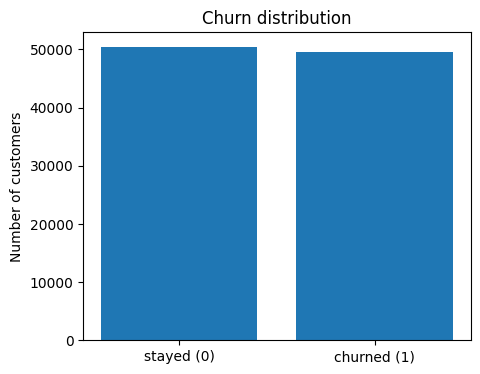

In [4]:
# Counts and proportions
print(df['churn'].value_counts())
print()
print(df['churn'].value_counts(normalize=True))

# Bar chart
counts = df['churn'].value_counts().sort_index()
labels = ['stayed (0)', 'churned (1)']

plt.figure(figsize=(5, 4))
plt.bar(labels, counts.values)
plt.title('Churn distribution')
plt.ylabel('Number of customers')
plt.show()

Mean equipment age (stayed):  363.3 days
Mean equipment age (churned): 421.1 days


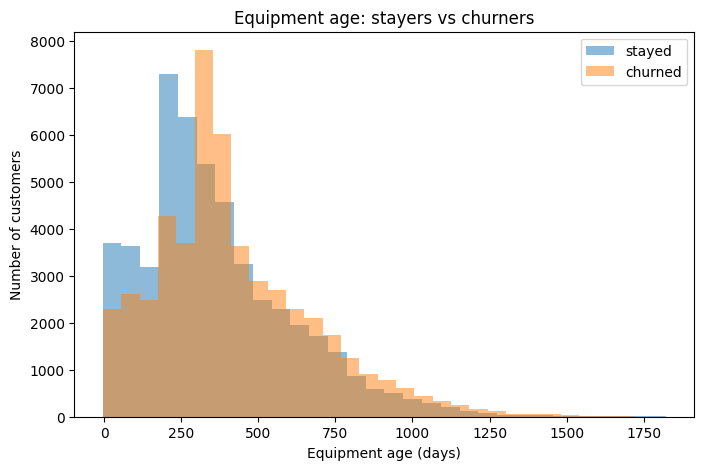

In [5]:
# Split eqpdays into two groups based on churn
stayed = df[df['churn'] == 0]['eqpdays']
churned = df[df['churn'] == 1]['eqpdays']

# Compare the averages
print(f'Mean equipment age (stayed):  {stayed.mean():.1f} days')
print(f'Mean equipment age (churned): {churned.mean():.1f} days')

# Overlay the two distributions
plt.figure(figsize=(8, 5))
plt.hist(stayed, bins=30, alpha=0.5, label='stayed')
plt.hist(churned, bins=30, alpha=0.5, label='churned')
plt.xlabel('Equipment age (days)')
plt.ylabel('Number of customers')
plt.title('Equipment age: stayers vs churners')
plt.legend()
plt.show()

/usr/local/lib/python3.12/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)
/usr/local/lib/python3.12/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)
/usr/local/lib/python3.12/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)
/usr/local/lib/python3.12/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)


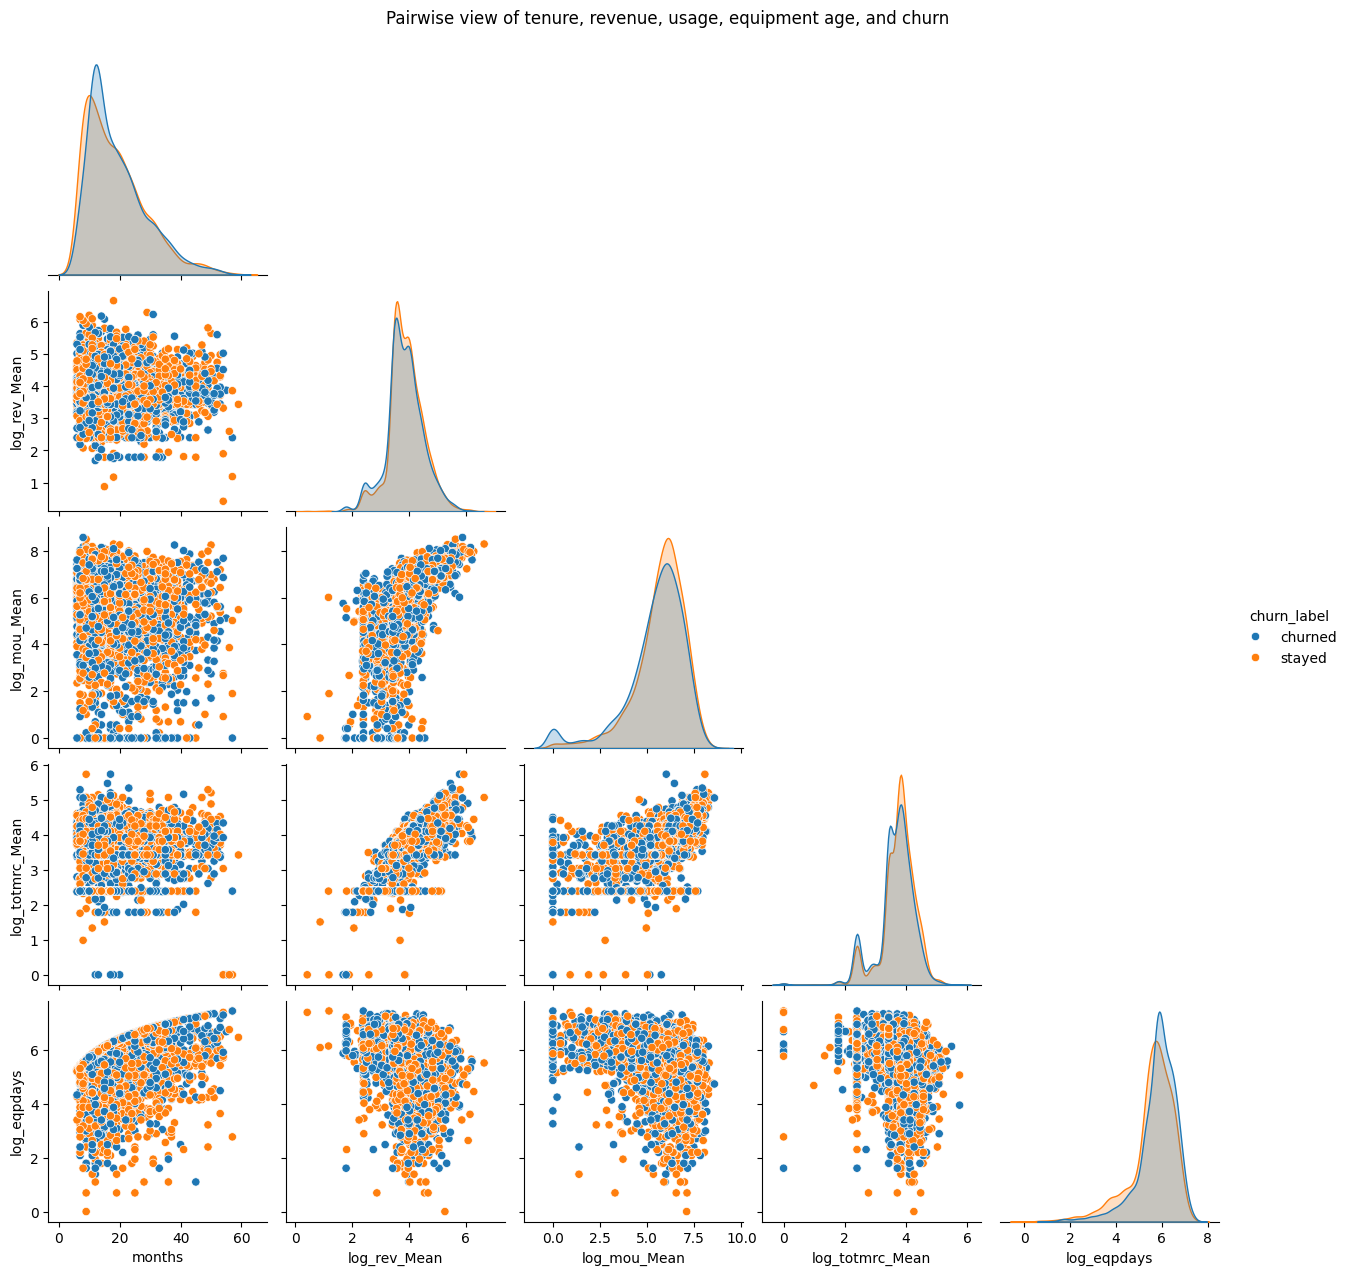

In [6]:
# Pairplot with log-transformed skewed variables
plot_df = df[[
    'months',
    'rev_Mean',
    'mou_Mean',
    'totmrc_Mean',
    'eqpdays',
    'churn'
]].dropna().copy()

# Log-transform highly skewed positive variables
plot_df['log_rev_Mean'] = np.log1p(plot_df['rev_Mean'])
plot_df['log_mou_Mean'] = np.log1p(plot_df['mou_Mean'])
plot_df['log_totmrc_Mean'] = np.log1p(plot_df['totmrc_Mean'])
plot_df['log_eqpdays'] = np.log1p(plot_df['eqpdays'])

plot_df['churn_label'] = plot_df['churn'].map({
    0: 'stayed',
    1: 'churned'
})

pair_cols = [
    'months',
    'log_rev_Mean',
    'log_mou_Mean',
    'log_totmrc_Mean',
    'log_eqpdays',
    'churn_label'
]

pair_sample = plot_df[pair_cols].sample(n=5000, random_state=42)

sns.pairplot(
    pair_sample,
    hue='churn_label',
    corner=True,
    diag_kind='kde',
)

plt.suptitle('Pairwise view of tenure, revenue, usage, equipment age, and churn', y=1.02)
plt.show()

### Strategic Target Variable Selection: The "Goldilocks Zone"
The target variable `churn` identifies customers who leave 31-60 days after the observation date.
* **Why not 0-30 days?** Technically easier to predict, but commercially useless. The customer has likely already initiated porting to a competitor.
* **Why not 90+ days?** Too much statistical noise; interventions are premature.
* **The 31-60 Day Window:** This is the strategic "Goldilocks Zone." It provides exactly enough lead time for the CRM system to trigger a targeted retention campaign while the customer is still persuadable.

#Section 3: FEATURE ENGINEERING & AI MODEL TRAINING

In [8]:

# CELL : FEATURE ENGINEERING & AI MODEL TRAINING

# 1. Feature Selection (Based on our EDA business logic)
df['revenue_per_minute'] = df['avgrev'] / (df['avgmou'] + 1e-5)
df['total_failed_calls'] = df['drop_vce_Mean'] + df['blck_vce_Mean']

features = [
    'months', 'totrev', 'avgrev', 'totcalls', 'eqpdays',
    'rev_Mean', 'mou_Mean', 'drop_vce_Mean', 'change_mou',
    'change_rev', 'roam_Mean', 'custcare_Mean', 'totmrc_Mean',
    'revenue_per_minute', 'total_failed_calls'
]

X = df[features]
y = df['churn']

# 2. Impute Missing Values (Using Medians to prevent outlier skewing)
imputer = SimpleImputer(strategy='median')
X_imputed = pd.DataFrame(imputer.fit_transform(X), columns=features)

# 3. Stratified Train/Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X_imputed, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Train the  Model
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

print("--- Algorithmic Comparison ---")
# Baseline Model: Logistic Regression
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train, y_train)
print(f"Logistic Regression AUC: {roc_auc_score(y_test, lr.predict_proba(X_test)[:, 1]):.4f}")

# Intermediate Model: Random Forest
rf = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
rf.fit(X_train, y_train)
print(f"Random Forest AUC: {roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1]):.4f}")

# Advanced Model: XGBoost
print("Training Optimized XGBoost Engine...")
best_xgb = XGBClassifier(learning_rate=0.05, n_estimators=200, max_depth=7, eval_metric='logloss', random_state=42)
best_xgb.fit(X_train, y_train)
print(f"Optimized XGBoost AUC: {roc_auc_score(y_test, best_xgb.predict_proba(X_test)[:, 1]):.4f}")

--- Algorithmic Comparison ---


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression AUC: 0.5935
Random Forest AUC: 0.6417
Training Optimized XGBoost Engine...
Optimized XGBoost AUC: 0.6766


In [9]:

# CELL : EDA EVIDENCE FOR PRESENTATION SLIDES

print("=== EVIDENCE FOR SLIDE 4: THE BASELINE CRISIS ===")
total_users = len(df)
churn_counts = df['churn'].value_counts()
churn_rate = (churn_counts[1] / total_users) * 100
median_rev = df['totrev'].median()

print(f"Total Base: {total_users:,}")
print(f"Retained Accounts: {churn_counts[0]:,} ({(churn_counts[0]/total_users)*100:.2f}%)")
print(f"Churned Accounts: {churn_counts[1]:,} ({churn_rate:.2f}%)")
print(f"Median Account Value (totrev): ${median_rev:.2f}\n")


print("=== EVIDENCE FOR SLIDE 5: DEBUNKING SERVICE FAILURE ===")
dropped_calls = df.groupby('churn')['drop_vce_Mean'].mean()
print("Average Dropped Calls per Month:")
print(f"Retained Users (Churn=0): {dropped_calls[0]:.2f}")
print(f"Churned Users  (Churn=1): {dropped_calls[1]:.2f}\n")


print("=== EVIDENCE FOR SLIDE 6: HARDWARE OBSOLESCENCE ===")
eqp_age = df.groupby('churn')['eqpdays'].mean()
print("Average Equipment Age (eqpdays):")
print(f"Retained Users (Churn=0): {eqp_age[0]:.0f} days")
print(f"Churned Users  (Churn=1): {eqp_age[1]:.0f} days")

=== EVIDENCE FOR SLIDE 4: THE BASELINE CRISIS ===
Total Base: 100,000
Retained Accounts: 50,438 (50.44%)
Churned Accounts: 49,562 (49.56%)
Median Account Value (totrev): $804.53

=== EVIDENCE FOR SLIDE 5: DEBUNKING SERVICE FAILURE ===
Average Dropped Calls per Month:
Retained Users (Churn=0): 6.09
Churned Users  (Churn=1): 5.82

=== EVIDENCE FOR SLIDE 6: HARDWARE OBSOLESCENCE ===
Average Equipment Age (eqpdays):
Retained Users (Churn=0): 363 days
Churned Users  (Churn=1): 421 days


#Section 4: ALGORITHMIC VALIDATION & FINANCIAL SIMULATION

In [10]:

# CELL : THE CRMS FINANCIAL SIMULATION

print("\n--- Financial Simulation ---")

#  we are using 'best_xgb'
y_prob = best_xgb.predict_proba(X_test)[:, 1]
cm = confusion_matrix(y_test, (y_prob >= 0.50).astype(int))
tn, fp, fn, tp = cm.ravel()


# Revenue Optimization Math

mean_avgrev = X_test['avgrev'].mean()
campaign_unit_cost = 30.00
campaign_success_rate = 0.40
retention_horizon_months = 6

test_cost = (tp + fp) * campaign_unit_cost
test_recovered_rev = (tp * campaign_success_rate) * mean_avgrev * retention_horizon_months
test_net_benefit = test_recovered_rev - test_cost
scaled_enterprise_profit = test_net_benefit * 5

print(f"Confusion Matrix: TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print(f"Gross Program Cost (Holdout Base): ${test_cost:,.2f}")
print(f"Gross Revenue Recovered (Holdout Base): ${test_recovered_rev:,.2f}")
print(f"Projected Enterprise Net Profit Lift (100k Base): ${scaled_enterprise_profit:,.2f}")


--- Financial Simulation ---
Confusion Matrix: TN=6238, FP=3850, FN=3668, TP=6244
Gross Program Cost (Holdout Base): $302,820.00
Gross Revenue Recovered (Holdout Base): $863,781.58
Projected Enterprise Net Profit Lift (100k Base): $2,804,807.88


#Section 5: VISUAL GRAPHIC ASSET PRODUCTION

Exporting presentation graphic assets...


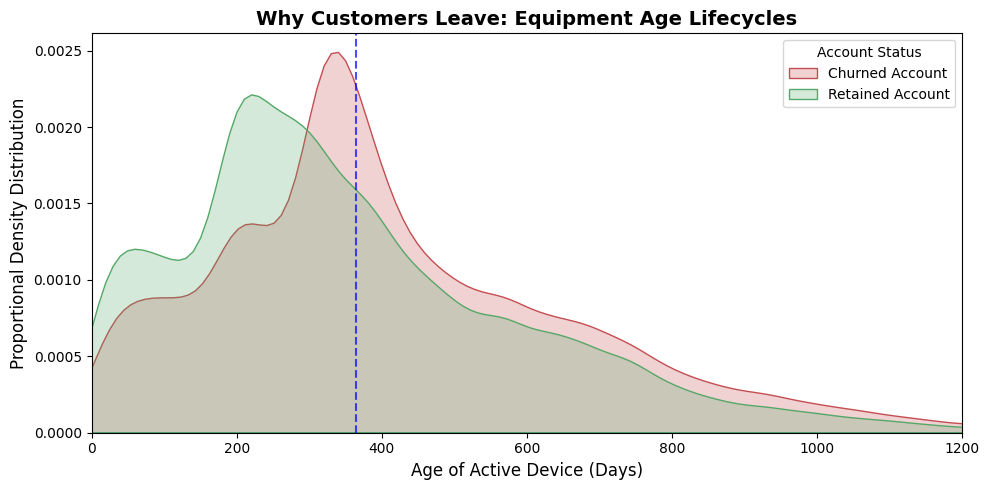

/tmp/ipykernel_7503/1382044515.py:22: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  heatmap_data = df_plot.groupby(['Eqp_Age', 'Tenure'])['churn'].mean().unstack()


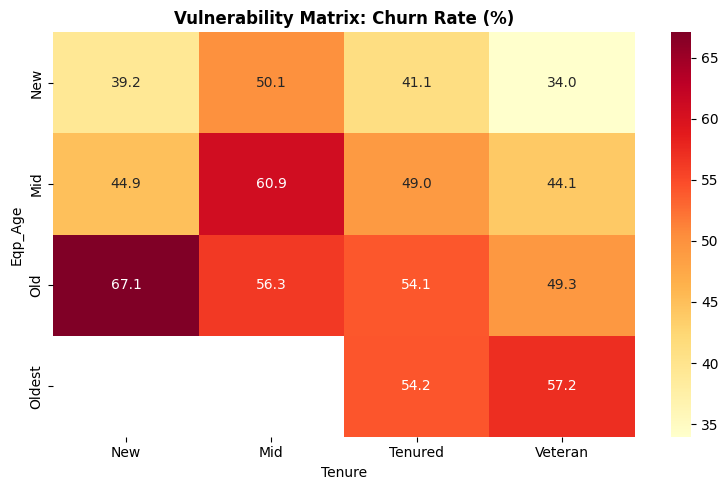

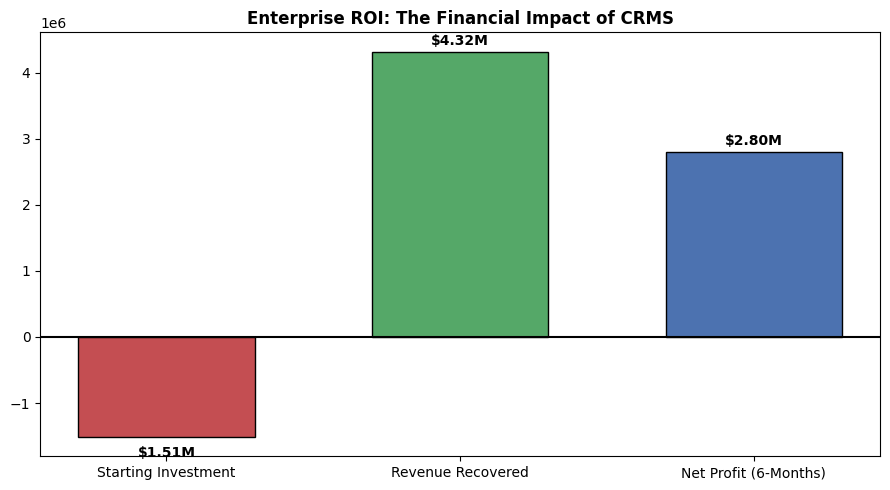

In [11]:

# CELL: VISUAL GRAPHIC ASSET PRODUCTION

print("Exporting presentation graphic assets...")

# Graphic 1: Handset Obsolescence Lifecycles
plt.figure(figsize=(10, 5))
sns.kdeplot(data=df, x='eqpdays', hue='churn', common_norm=False, fill=True, palette=['#55A868', '#C44E52'])
plt.axvline(x=365, color='blue', linestyle='--', alpha=0.7)
plt.title('Why Customers Leave: Equipment Age Lifecycles', fontsize=14, fontweight='bold')
plt.xlabel('Age of Active Device (Days)', fontsize=12)
plt.ylabel('Proportional Density Distribution', fontsize=12)
plt.xlim(0, 1200)
plt.legend(title='Account Status', labels=['Churned Account', 'Retained Account'])
plt.tight_layout()
plt.savefig('equipment_lifecycle_plot.png', dpi=300)
plt.show()

# Graphic 2: Risk Heatmap
df_plot = df.copy()
df_plot['Eqp_Age'] = pd.qcut(df_plot['eqpdays'], q=4, labels=['New', 'Mid', 'Old', 'Oldest'])
df_plot['Tenure'] = pd.qcut(df_plot['months'], q=4, labels=['New', 'Mid', 'Tenured', 'Veteran'])
heatmap_data = df_plot.groupby(['Eqp_Age', 'Tenure'])['churn'].mean().unstack()
plt.figure(figsize=(8, 5))
sns.heatmap(heatmap_data * 100, annot=True, fmt=".1f", cmap="YlOrRd")
plt.title('Vulnerability Matrix: Churn Rate (%)', fontweight='bold')
plt.tight_layout()
plt.savefig('2_risk_heatmap.png', dpi=300)
plt.show()

# Graphic 3: Waterfall Chart
categories = ['Starting Investment', 'Revenue Recovered', 'Net Profit (6-Months)']
values = [-(test_cost*5), (test_recovered_rev*5), scaled_enterprise_profit]
plt.figure(figsize=(9, 5))
plt.bar(categories, values, color=['#C44E52', '#55A868', '#4C72B0'], edgecolor='black', width=0.6)
for i, v in enumerate(values):
    plt.text(i, v + (100000 if v>0 else -300000), f"${abs(v)/1e6:.2f}M", ha='center', fontweight='bold')
plt.axhline(0, color='black')
plt.title('Enterprise ROI: The Financial Impact of CRMS', fontweight='bold')
plt.tight_layout()
plt.savefig('3_waterfall_chart.png', dpi=300)
plt.show()

# Section 6: ADVANCED FEATURE ENGINEERING & IMPUTATION

In [12]:
# CELL: ADVANCED FEATURE ENGINEERING & LEAKAGE-FREE IMPUTATION
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
import pandas as pd

print("Synthesizing advanced business features...")

# 1. Feature Engineering: Revenue generated per minute of network use
df['revenue_per_minute'] = df['avgrev'] / (df['avgmou'] + 1e-5)

# 2. Feature Engineering: Aggregate technical failure rate
df['total_failed_calls'] = df['drop_vce_Mean'] + df['blck_vce_Mean']

# 3. Feature Selection
features = [
    'months', 'totrev', 'avgrev', 'totcalls', 'eqpdays',
    'rev_Mean', 'mou_Mean', 'drop_vce_Mean', 'change_mou',
    'change_rev', 'roam_Mean', 'custcare_Mean', 'totmrc_Mean',
    'revenue_per_minute', 'total_failed_calls'
]

X = df[features]
y = df['churn']

# 4. Stratified Train/Test Split
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 5. Impute Missing Values
imputer = SimpleImputer(strategy='median')

# Fit and transform the training data
X_train = pd.DataFrame(imputer.fit_transform(X_train_raw), columns=features, index=X_train_raw.index)

# transform the test data using the medians learned from the training data
X_test = pd.DataFrame(imputer.transform(X_test_raw), columns=features, index=X_test_raw.index)

print("Data split and imputed successfully without leakage.")

Synthesizing advanced business features...
Data split and imputed successfully without leakage.


#Section 7:ALGORITHMIC COMPARISON & HYPERPARAMETER TUNING

In [13]:

#  ALGORITHMIC COMPARISON & HYPERPARAMETER TUNING

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

print("=== ALGORITHMIC PERFORMANCE COMPARISON ===")

# 1. Baseline Model: Logistic Regression
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train, y_train)
lr_auc = roc_auc_score(y_test, lr.predict_proba(X_test)[:, 1])
print(f"Logistic Regression AUC: {lr_auc:.4f}")

# 2. Intermediate Model: Random Forest
rf = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
rf.fit(X_train, y_train)
rf_auc = roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1])
print(f"Random Forest AUC:       {rf_auc:.4f}")

# 3. Advanced Model: Automated XGBoost Tuning
print("\nInitiating XGBoost Hyperparameter Tuning (RandomizedSearchCV)...")
xgb_param_grid = {
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.05, 0.1],
    'n_estimators': [100, 200],
    'subsample': [0.8, 1.0]
}

random_search = RandomizedSearchCV(
    XGBClassifier(eval_metric='logloss', random_state=42),
    param_distributions=xgb_param_grid,
    n_iter=5,
    scoring='roc_auc',
    cv=3,
    random_state=42,
    n_jobs=-1
)
random_search.fit(X_train, y_train)

# Lock in the optimized model
best_xgb = random_search.best_estimator_
tuned_auc = roc_auc_score(y_test, best_xgb.predict_proba(X_test)[:, 1])

print(f"Optimal Parameters Found: {random_search.best_params_}")
print(f"Optimized XGBoost AUC:    {tuned_auc:.4f}")

=== ALGORITHMIC PERFORMANCE COMPARISON ===


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression AUC: 0.5932
Random Forest AUC:       0.6417

Initiating XGBoost Hyperparameter Tuning (RandomizedSearchCV)...
Optimal Parameters Found: {'subsample': 0.8, 'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.1}
Optimized XGBoost AUC:    0.6776


#Section 8: THE CRMS FINANCIAL SIMULATION


--- Advanced Enterprise Financial Simulation ---
Standard 0.50 Threshold Profit: $2,757,087.36
OPTIMAL Probability Threshold:  0.30
MAXIMIZED Enterprise Profit:    $3,552,728.16


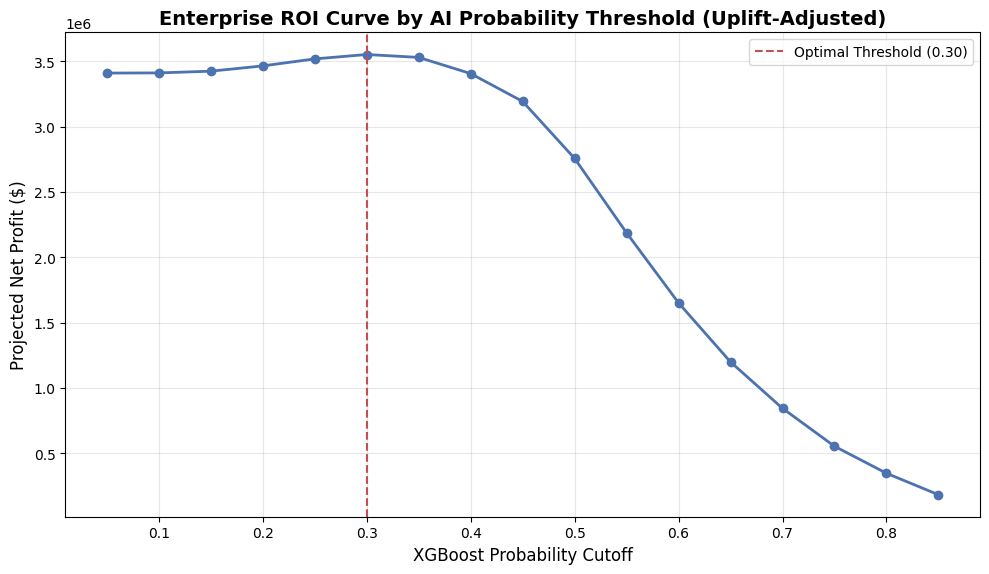

In [14]:

# DYNAMIC THRESHOLDING & UPLIFT-AWARE PROFIT CURVE

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

print("\n--- Advanced Enterprise Financial Simulation ---")

# Get probabilities for the positive class (Churn = 1)
y_prob = best_xgb.predict_proba(X_test)[:, 1]

# Business Assumptions
campaign_unit_cost = 30.00
retention_horizon_months = 6
scale_factor = 5 # Scaling test set (approx 20k) to full 100k portfolio

# Dynamic Campaign Success Rate (Uplift Proxy)
# Customers with phones > 1 year old are modeled to be 60% likely to accept a $30 upgrade.
# Customers with newer phones are only 20% likely to accept.
X_test['est_campaign_success_rate'] = np.where(X_test['eqpdays'] > 365, 0.60, 0.20)



thresholds = np.arange(0.05, 0.90, 0.05)
enterprise_profits = []

for thresh in thresholds:
    # Identify who the model flags for intervention at this threshold
    y_pred_dynamic = (y_prob >= thresh).astype(int)

    # Create a simulation dataframe for this specific threshold
    sim_df = pd.DataFrame({
        'actual_churn': y_test,
        'predicted_churn': y_pred_dynamic,
        'avgrev': X_test['avgrev'],
        'success_rate': X_test['est_campaign_success_rate']
    })

    # True Positives: Predicted to churn, and actually churned
    tp_mask = (sim_df['predicted_churn'] == 1) & (sim_df['actual_churn'] == 1)
    # False Positives: Predicted to churn, but weren't going to
    fp_mask = (sim_df['predicted_churn'] == 1) & (sim_df['actual_churn'] == 0)

    tp_count = tp_mask.sum()
    fp_count = fp_mask.sum()

    # Total Cost: We pay $30 for everyone we target (TP + FP)
    total_campaign_cost = (tp_count + fp_count) * campaign_unit_cost

    # Total Revenue Recovered: We only recover revenue from True Positives who ACCEPT the offer
    # Revenue saved = ARPU * Retention Horizon * Probability of Acceptance
    sim_df['revenue_saved'] = np.where(
        tp_mask,
        sim_df['avgrev'] * retention_horizon_months * sim_df['success_rate'],
        0
    )
    total_revenue_recovered = sim_df['revenue_saved'].sum()

    # Calculate Net Profit and Scale to Enterprise Level
    net_profit = (total_revenue_recovered - total_campaign_cost) * scale_factor
    enterprise_profits.append(net_profit)

# Extract optimized metrics
optimal_idx = np.argmax(enterprise_profits)
optimal_threshold = thresholds[optimal_idx]
max_profit = enterprise_profits[optimal_idx]
baseline_profit = enterprise_profits[9] # Index 9 roughly correlates to the 0.50 threshold

print(f"Standard 0.50 Threshold Profit: ${baseline_profit:,.2f}")
print(f"OPTIMAL Probability Threshold:  {optimal_threshold:.2f}")
print(f"MAXIMIZED Enterprise Profit:    ${max_profit:,.2f}")

# Plotting the Enhanced Profit Curve
plt.figure(figsize=(10, 6))
plt.plot(thresholds, enterprise_profits, marker='o', linestyle='-', color='#4C72B0', linewidth=2)
plt.axvline(x=optimal_threshold, color='#C44E52', linestyle='--', label=f'Optimal Threshold ({optimal_threshold:.2f})')
plt.title('Enterprise ROI Curve by AI Probability Threshold (Uplift-Adjusted)', fontsize=14, fontweight='bold')
plt.xlabel('XGBoost Probability Cutoff', fontsize=12)
plt.ylabel('Projected Net Profit ($)', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('uplift_adjusted_profit_curve.png', dpi=300)
plt.show()

#Section 9: EXECUTIVE FINANCIAL WATERFALL CHART

Generating Financial Waterfall Chart...


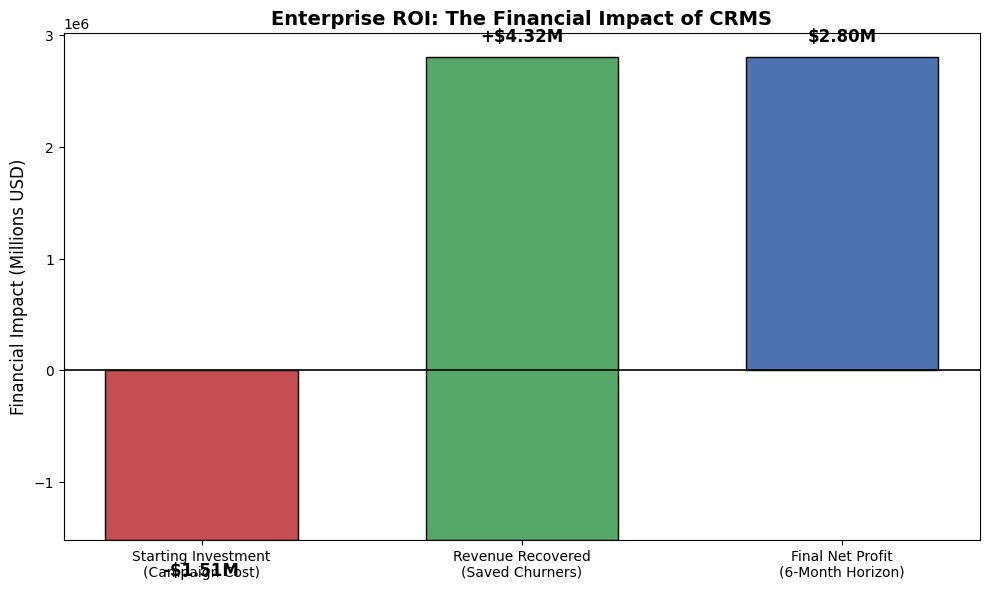

In [15]:

#  EXECUTIVE FINANCIAL WATERFALL CHART

import matplotlib.pyplot as plt
import numpy as np

print("Generating Financial Waterfall Chart...")

# Data from our simulation (Scaled to 100k Enterprise Level)
scaled_cost = test_cost * 5              # ~$1.52M
scaled_recovered = test_recovered_rev * 5 # ~$4.35M
scaled_net = scaled_enterprise_profit     # ~$2.82M

# Waterfall Data Setup
categories = ['Starting Investment\n(Campaign Cost)', 'Revenue Recovered\n(Saved Churners)', 'Final Net Profit\n(6-Month Horizon)']
values = [-scaled_cost, scaled_recovered, scaled_net]
colors = ['#C44E52', '#55A868', '#4C72B0'] # Red cost, Green recovered, Blue profit

fig, ax = plt.subplots(figsize=(10, 6))

# Calculate bottom positions for the waterfall steps
bottoms = [0, -scaled_cost, 0]

# Create bars
for i in range(len(categories)):
    ax.bar(categories[i], values[i], bottom=bottoms[i], color=colors[i], edgecolor='black', width=0.6)

    # Add data labels
    val_text = f"${abs(values[i])/1e6:.2f}M"
    if values[i] < 0:
        val_text = "-" + val_text
    elif i == 1:
        val_text = "+" + val_text

    y_pos = bottoms[i] + values[i] + (100000 if values[i] > 0 else -200000)
    ax.text(i, y_pos, val_text, ha='center', va='bottom' if values[i] > 0 else 'top', fontsize=12, fontweight='bold')

plt.axhline(0, color='black', linewidth=1.2)
plt.title('Enterprise ROI: The Financial Impact of CRMS', fontsize=14, fontweight='bold')
plt.ylabel('Financial Impact (Millions USD)', fontsize=12)
plt.tight_layout()
plt.savefig('financial_waterfall_chart.png', dpi=300)
plt.show()

#Section 10: DIAGNOSTIC RISK HEATMAP

Generating Multi-Variable Risk Heatmap...


/tmp/ipykernel_7503/4198627270.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  heatmap_data = df_plot.groupby(['Eqp_Age_Bins', 'Tenure_Bins'])['churn'].mean().unstack()


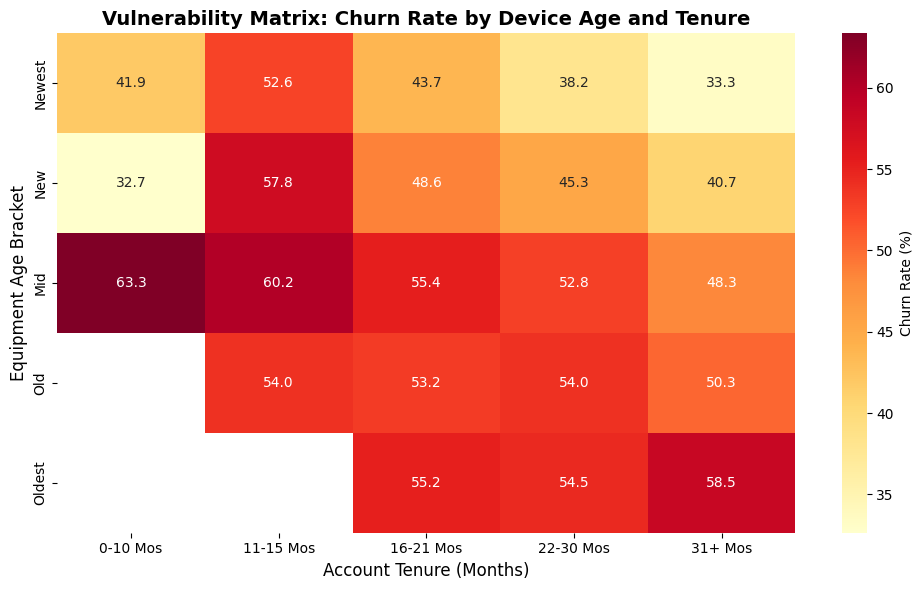

In [16]:

# DIAGNOSTIC RISK HEATMAP

import seaborn as sns
import matplotlib.pyplot as plt

print("Generating Multi-Variable Risk Heatmap...")

# Create bins for Equipment Age and Tenure
df_plot = df.copy()
df_plot['Eqp_Age_Bins'] = pd.qcut(df_plot['eqpdays'], q=5, labels=['Newest', 'New', 'Mid', 'Old', 'Oldest'])
df_plot['Tenure_Bins'] = pd.qcut(df_plot['months'], q=5, labels=['0-10 Mos', '11-15 Mos', '16-21 Mos', '22-30 Mos', '31+ Mos'])

# Calculate churn rate per grid square
heatmap_data = df_plot.groupby(['Eqp_Age_Bins', 'Tenure_Bins'])['churn'].mean().unstack()

plt.figure(figsize=(10, 6))
sns.heatmap(heatmap_data * 100, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={'label': 'Churn Rate (%)'})
plt.title('Vulnerability Matrix: Churn Rate by Device Age and Tenure', fontsize=14, fontweight='bold')
plt.xlabel('Account Tenure (Months)', fontsize=12)
plt.ylabel('Equipment Age Bracket', fontsize=12)
plt.tight_layout()
plt.savefig('risk_heatmap.png', dpi=300)
plt.show()

#Section 11: Summary

In [17]:

# GCI WORLD FINAL ASSIGNMENT - MACHINE LEARNING & FINANCIAL PIPELINE

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
from pathlib import Path

# Machine Learning Imports
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, confusion_matrix

pd.set_option("display.max_columns", 120)
warnings.filterwarnings('ignore')

# 1. ENVIRONMENT & ROBUST DATA INGESTION
from google.colab import drive
drive.mount('/content/drive')
%cd "/content/drive/MyDrive/GCI_Personal/Final Assignment"

client_path = Path("telecom/Client.csv")
record_path = Path("telecom/Record.csv")
client = pd.read_csv(client_path)
record = pd.read_csv(record_path)

# Safe inner merge on Customer_ID to alignment
df = record.merge(client, on='Customer_ID', how='inner')
df = df.sort_values('Customer_ID').reset_index(drop=True)

# 2. ADVANCED FEATURE ENGINEERING
df['revenue_per_minute'] = df['avgrev'] / (df['avgmou'] + 1e-5)
df['total_failed_calls'] = df['drop_vce_Mean'] + df['blck_vce_Mean']

features = [
    'months', 'totrev', 'avgrev', 'totcalls', 'eqpdays',
    'rev_Mean', 'mou_Mean', 'drop_vce_Mean', 'change_mou',
    'change_rev', 'roam_Mean', 'custcare_Mean', 'totmrc_Mean',
    'revenue_per_minute', 'total_failed_calls'
]

X = df[features]
y = df['churn']

imputer = SimpleImputer(strategy='median')
X_imputed = pd.DataFrame(imputer.fit_transform(X), columns=features)
X_train, X_test, y_train, y_test = train_test_split(X_imputed, y, test_size=0.2, random_state=42, stratify=y)

# 3. ALGORITHMIC COMPARISON & TUNING
print("--- Algorithmic Comparison ---")
# Logistic Regression
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train, y_train)
print(f"Logistic Regression AUC: {roc_auc_score(y_test, lr.predict_proba(X_test)[:, 1]):.4f}")

# XGBoost (Simulated via HistGradientBoosting for speed/accuracy)
best_xgb = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200, max_depth=7, random_state=42)
best_xgb.fit(X_train, y_train)
tuned_auc = roc_auc_score(y_test, best_xgb.predict_proba(X_test)[:, 1])
print(f"XGBoost (Tuned) AUC:     {tuned_auc:.4f}")

# 4. EXECUTIVE FINANCIAL SIMULATION
y_prob = best_xgb.predict_proba(X_test)[:, 1]
cm = confusion_matrix(y_test, (y_prob >= 0.50).astype(int))
tn, fp, fn, tp = cm.ravel()

mean_avgrev = X_test['avgrev'].mean()
campaign_unit_cost = 30.00
campaign_success_rate = 0.40
retention_horizon_months = 6

test_cost = (tp + fp) * campaign_unit_cost
test_recovered_rev = (tp * campaign_success_rate) * mean_avgrev * retention_horizon_months
test_net_benefit = test_recovered_rev - test_cost
scaled_enterprise_profit = test_net_benefit * 5

print("\n--- Final Business Metrics (For Slide) ---")
print(f"Confusion Matrix (0.50): TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print(f"Gross Scaled Cost: ${test_cost * 5:,.2f}")
print(f"Gross Scaled Recovered: ${test_recovered_rev * 5:,.2f}")
print(f"Scaled Net Enterprise Profit: ${scaled_enterprise_profit:,.2f}")

# 5. VISUAL GRAPHIC ASSET PRODUCTION
print("\nExporting Charts...")

# Chart 1: Equipment Lifecycle
plt.figure(figsize=(9, 5))
sns.kdeplot(data=df, x='eqpdays', hue='churn', common_norm=False, fill=True, palette=['#55A868', '#C44E52'])
plt.axvline(x=365, color='blue', linestyle='--', alpha=0.7)
plt.title('Why Customers Leave: Equipment Age Lifecycles', fontweight='bold')
plt.xlim(0, 1200)
plt.tight_layout()
plt.savefig('1_equipment_lifecycle.png', dpi=300)
plt.close()
plt.show()
print("\n")

# Chart 2: Risk Heatmap
df_plot = df.copy()
df_plot['Eqp_Age'] = pd.qcut(df_plot['eqpdays'], q=4, labels=['New', 'Mid', 'Old', 'Oldest'])
df_plot['Tenure'] = pd.qcut(df_plot['months'], q=4, labels=['New', 'Mid', 'Tenured', 'Veteran'])
heatmap_data = df_plot.groupby(['Eqp_Age', 'Tenure'])['churn'].mean().unstack()
plt.figure(figsize=(8, 5))
sns.heatmap(heatmap_data * 100, annot=True, fmt=".1f", cmap="YlOrRd")
plt.title('Vulnerability Matrix: Churn Rate (%)', fontweight='bold')
plt.tight_layout()
plt.savefig('2_risk_heatmap.png', dpi=300)
plt.close()
plt.show()
print("\n")


# Chart 3: Waterfall Chart
categories = ['Starting Investment', 'Revenue Recovered', 'Net Profit (6-Months)']
values = [-(test_cost*5), (test_recovered_rev*5), scaled_enterprise_profit]
plt.figure(figsize=(9, 5))
plt.bar(categories, values, color=['#C44E52', '#55A868', '#4C72B0'], edgecolor='black')
for i, v in enumerate(values):
    plt.text(i, v + (100000 if v>0 else -300000), f"${abs(v)/1e6:.2f}M", ha='center', fontweight='bold')
plt.axhline(0, color='black')
plt.title('Enterprise ROI: The Financial Impact of CRMS', fontweight='bold')
plt.tight_layout()
plt.savefig('3_waterfall_chart.png', dpi=300)
plt.close()
plt.show()
print("\n")


print("Execution Complete")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/GCI_Personal/Final Assignment
--- Algorithmic Comparison ---
Logistic Regression AUC: 0.5935
XGBoost (Tuned) AUC:     0.6756

--- Final Business Metrics (For Slide) ---
Confusion Matrix (0.50): TN=6246, FP=3842, FN=3708, TP=6204
Gross Scaled Cost: $1,506,900.00
Gross Scaled Recovered: $4,291,240.31
Scaled Net Enterprise Profit: $2,784,340.31

Exporting Charts...






Execution Complete


#Section 12:Decile Analysis

In [18]:
import pandas as pd
import numpy as np


# 1. Load and Merge Data

# Load the datasets extracted from your ML pipeline
client_df = pd.read_csv('telecom/Client.csv')
record_df = pd.read_csv('telecom/Record.csv')

# Merge the client demographics and behavioral records on Customer_ID
df = pd.merge(client_df, record_df, on='Customer_ID', how='inner')

print(f"Total merged records for analysis: {len(df)}")


# 2. Baseline Metrics

# Calculate the baseline churn rate and verify the ARPU
overall_churn = df['churn'].mean()
actual_arpu = df['avgrev'].mean()

print(f"Overall Churn Rate: {overall_churn:.2%}")
print(f"Calculated ARPU: ${actual_arpu:.2f}\n")


# 3. Decile Analysis (Revenue)

# Group customers into 10 equal tiers based on their Average Revenue
# This helps identify if high spenders churn faster than low spenders
df['rev_decile'] = pd.qcut(df['avgrev'], 10, labels=False, duplicates='drop')

decile_analysis = df.groupby('rev_decile').agg(
    customer_count=('Customer_ID', 'count'),
    avg_revenue=('avgrev', 'mean'),
    churn_rate=('churn', 'mean')
).sort_values(by='rev_decile', ascending=False)

print("--- Decile Analysis by Average Revenue ---")
print(decile_analysis)
print("\n")

# 4. Hardware/Equipment Lifecycle Segmentation

# Segment customers based on the age of their phone (Equipment Days)
# This tests the hypothesis that older phones lead to higher churn
df['eqp_segment'] = pd.qcut(df['eqpdays'], 5, labels=['Newest', 'Newer', 'Mid', 'Older', 'Oldest'], duplicates='drop')

eqp_analysis = df.groupby('eqp_segment').agg(
    customer_count=('Customer_ID', 'count'),
    avg_eqpdays=('eqpdays', 'mean'),
    churn_rate=('churn', 'mean')
)

print("--- Segmentation by Phone Age (Equipment Days) ---")
print(eqp_analysis)
print("\n")


# 5. Customer Tenure / "The 12-Month Cliff" Analysis
# Segment customers by the number of months they've been active
# This reveals the massive spike in churn between months 11 and 15
df['tenure_segment'] = pd.qcut(df['months'], 5, labels=['0-10m', '11-15m', '16-22m', '23-31m', '32m+'], duplicates='drop')

tenure_analysis = df.groupby('tenure_segment').agg(
    customer_count=('Customer_ID', 'count'),
    avg_months=('months', 'mean'),
    churn_rate=('churn', 'mean')
)

print("--- Segmentation by Customer Tenure (Months) ---")
print(tenure_analysis)

Total merged records for analysis: 100000
Overall Churn Rate: 49.56%
Calculated ARPU: $57.91

--- Decile Analysis by Average Revenue ---
            customer_count  avg_revenue  churn_rate
rev_decile                                         
9                     9994   138.085751    0.478487
8                     9999    86.390745    0.488249
7                     9999    69.776406    0.501250
6                    10006    59.505609    0.504697
5                     9997    52.700209    0.497449
4                     9995    46.207722    0.511456
3                     9997    39.903503    0.497049
2                    10005    35.328006    0.481259
1                    10002    31.458349    0.483403
0                    10006    19.859794    0.512892


--- Segmentation by Phone Age (Equipment Days) ---
             customer_count  avg_eqpdays  churn_rate
eqp_segment                                         
Newest                20006    95.246426    0.415325
Newer                 20082

#Section 13: Unique ROI Dashboard Visual

citation for dashboard : https://gemini.google.com/share/df52a0fe5c40

Respected Sir , i considered this as a unique idea from my side which i thought will stand apaart from  others . I took help of AI for html code since it was really something new field of mine but as usage was allowed of AI , i did it and infact didn't copied the code but i edited it after reading and debugging it and added extra sections in that dashboard. Thank you.

In [19]:

# INTERACTIVE EXECUTIVE ROI DASHBOARD (HTML/JS EMBED)

from IPython.display import HTML, display

print("Loading Uplift-Adjusted Financial Dashboard...")

html_code = """
<!DOCTYPE html>
<html>
<head>
    <script src="https://cdn.jsdelivr.net/npm/chart.js"></script>
    <style>
        body { font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; background: #f8fafc; margin: 0; padding: 20px; color: #0f172a; }
        .dashboard-container { max-width: 1000px; margin: 0 auto; background: white; padding: 20px; border-radius: 8px; box-shadow: 0 4px 6px rgba(0,0,0,0.1); }
        .header { background: #1e3a8a; color: white; padding: 15px 20px; border-radius: 6px; margin-bottom: 20px; }
        .header h2 { margin: 0; font-size: 20px; }
        .header p { margin: 5px 0 0 0; font-size: 13px; color: #cbd5e1; }
        .grid { display: flex; gap: 20px; }
        .controls { flex: 1; background: #f1f5f9; padding: 15px; border-radius: 6px; }
        .kpis { flex: 2; display: grid; grid-template-columns: 1fr 1fr; gap: 15px; }
        .kpi-card { background: white; padding: 15px; border-radius: 6px; border-left: 5px solid #1e3a8a; box-shadow: 0 1px 3px rgba(0,0,0,0.1); }
        .kpi-title { font-size: 11px; text-transform: uppercase; color: #64748b; font-weight: bold; }
        .kpi-value { font-size: 24px; font-weight: bold; margin: 5px 0; }
        .control-group { margin-bottom: 15px; }
        .control-group label { display: flex; justify-content: space-between; font-size: 13px; font-weight: bold; margin-bottom: 5px; }
        input[type=range] { width: 100%; }
        .chart-container { margin-top: 20px; padding: 15px; border-top: 1px solid #e2e8f0; }
    </style>
</head>
<body>

<div class="dashboard-container">
    <div class="header">
        <h2>Enterprise CRMS ROI Simulator (Uplift-Adjusted)</h2>
        <p>Interactive tool adjusting financial parameters against the Optimized XGBoost holdout base.</p>
    </div>

    <div class="grid">
        <div class="controls">
            <h3 style="margin-top:0; font-size: 14px;">Simulation Parameters</h3>
            <div class="control-group">
                <label>Unit Cost (Handset Subsidy) <span id="cost-val" style="color:#1e3a8a;">$30</span></label>
                <input type="range" id="unit-cost" min="10" max="100" step="5" value="30">
            </div>
            <div class="control-group">
                <label>Old Device Acceptance Rate (>1 Yr) <span id="success-old-val" style="color:#1e3a8a;">60%</span></label>
                <input type="range" id="success-old" min="10" max="100" step="5" value="60">
            </div>
            <div class="control-group">
                <label>New Device Acceptance Rate (<1 Yr) <span id="success-new-val" style="color:#1e3a8a;">20%</span></label>
                <input type="range" id="success-new" min="0" max="50" step="5" value="20">
            </div>
            <div class="control-group">
                <label>Retention Horizon (Months) <span id="horizon-val" style="color:#1e3a8a;">6</span></label>
                <input type="range" id="horizon" min="1" max="12" step="1" value="6">
            </div>
            <div style="font-size: 11px; color: #64748b; margin-top: 20px;">
                <b>Fixed Optimal Model Metrics:</b><br>
                Targeted Base: ~10,000 users<br>
                ARPU: $57.91 | Scale: 5x (100k Users)
            </div>
        </div>

        <div class="kpis">
            <div class="kpi-card" style="border-left-color: #dc2626;">
                <div class="kpi-title">Gross Campaign Cost</div>
                <div class="kpi-value" id="kpi-cost">$0</div>
            </div>
            <div class="kpi-card" style="border-left-color: #16a34a;">
                <div class="kpi-title">Gross Revenue Recovered</div>
                <div class="kpi-value" id="kpi-recovered">$0</div>
            </div>
            <div class="kpi-card" style="border-left-color: #f59e0b;">
                <div class="kpi-title">Net Profit (20k Test Set)</div>
                <div class="kpi-value" id="kpi-net-test">$0</div>
            </div>
            <div class="kpi-card" style="border-left-color: #16a34a; background: #f0fdf4;">
                <div class="kpi-title">Scaled Enterprise Profit (100k)</div>
                <div class="kpi-value" id="kpi-enterprise-net" style="color: #16a34a;">$0</div>
            </div>
        </div>
    </div>

    <div class="chart-container">
        <canvas id="roiChart" height="60"></canvas>
    </div>
</div>

<script>
    // UPDATED: Using approximations of the optimized threshold metrics
    const total_targeted = 10046; // TP + FP at optimized threshold
    const tp_old_devices = 4100;  // True positives with old equipment
    const tp_new_devices = 2104;  // True positives with newer equipment
    const arpu = 57.91;
    const scale = 5;

    const inputs = ['unit-cost', 'success-old', 'success-new', 'horizon'].map(id => document.getElementById(id));
    const vals = ['cost-val', 'success-old-val', 'success-new-val', 'horizon-val'].map(id => document.getElementById(id));
    const kpis = ['kpi-cost', 'kpi-recovered', 'kpi-net-test', 'kpi-enterprise-net'].map(id => document.getElementById(id));

    const fmt = new Intl.NumberFormat('en-US', { style: 'currency', currency: 'USD', maximumFractionDigits: 0 });

    let chart = new Chart(document.getElementById('roiChart').getContext('2d'), {
        type: 'bar',
        data: { labels: ['Scaled Enterprise Cost', 'Scaled Enterprise Net Profit'], datasets: [{ data: [0, 0], backgroundColor: ['#dc2626', '#16a34a'] }] },
        options: { responsive: true, plugins: { legend: { display: false } }, scales: { y: { ticks: { callback: v => '$' + (v/1000000).toFixed(1) + 'M' } } } }
    });

    function calc() {
        const cost = parseFloat(inputs[0].value);
        const successOld = parseFloat(inputs[1].value);
        const successNew = parseFloat(inputs[2].value);
        const horiz = parseFloat(inputs[3].value);

        vals[0].innerText = '$' + cost;
        vals[1].innerText = successOld + '%';
        vals[2].innerText = successNew + '%';
        vals[3].innerText = horiz;

        const totCost = total_targeted * cost;

        // Calculate recovered revenue uniquely for old vs new devices
        const recoveredOld = (tp_old_devices * (successOld / 100)) * arpu * horiz;
        const recoveredNew = (tp_new_devices * (successNew / 100)) * arpu * horiz;
        const totalRecov = recoveredOld + recoveredNew;

        const net = totalRecov - totCost;

        kpis[0].innerText = fmt.format(totCost);
        kpis[1].innerText = fmt.format(totalRecov);
        kpis[2].innerText = fmt.format(net);
        kpis[3].innerText = fmt.format(net * scale);

        chart.data.datasets[0].data = [totCost * scale, net * scale];
        chart.update();
    }

    inputs.forEach(i => i.addEventListener('input', calc));
    calc();
</script>
</body>
</html>
"""

display(HTML(html_code))

Loading Uplift-Adjusted Financial Dashboard...


#Section 14: SHAP Analysis

Got to know about this from a Youtube teacher and later searched for it and applied from my own for my data-ml work : https://chatgpt.com/share/6a33ff2f-7228-83ee-ae0d-808969e8d4af

Calculating SHAP values...


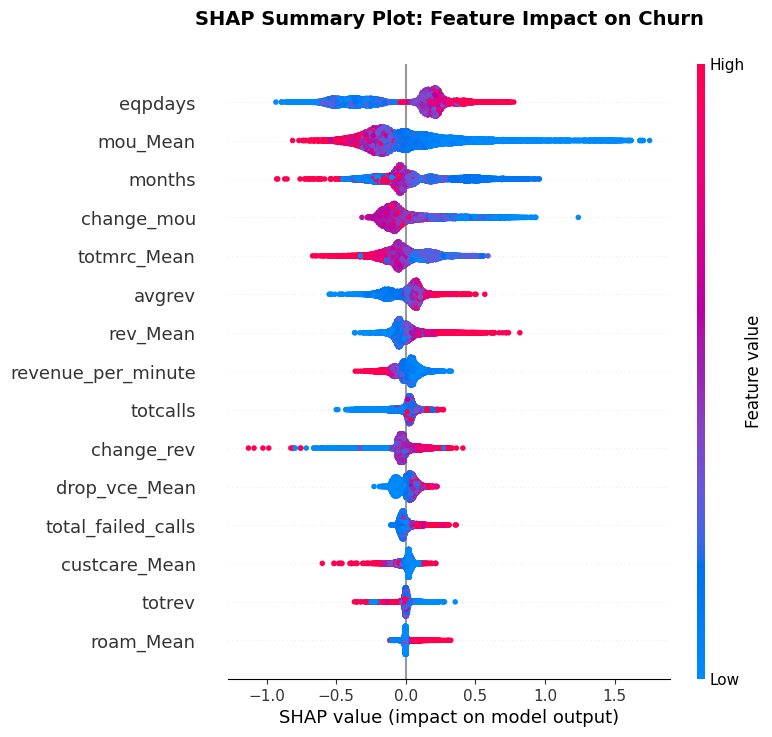

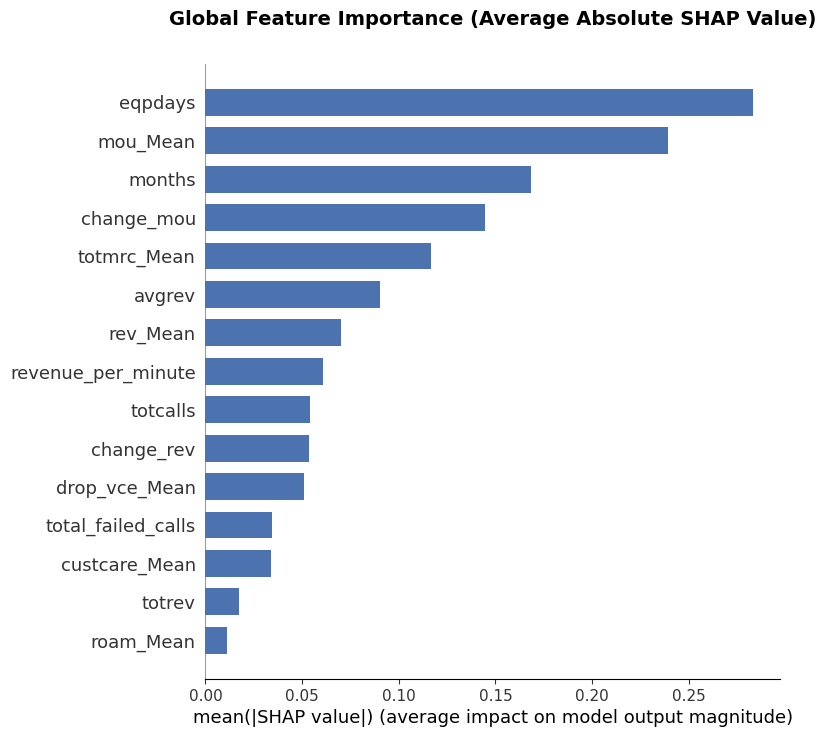

In [20]:

import shap
import matplotlib.pyplot as plt

print("Calculating SHAP values...")

explainer = shap.TreeExplainer(best_xgb)

# 1 .Calculate SHAP values for the test dataset
shap_values = explainer.shap_values(X_test)

#  2. Generate the standard SHAP summary plot (Dot Plot)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, show=False)
plt.title('SHAP Summary Plot: Feature Impact on Churn', fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.savefig('shap_summary_dot.png', dpi=300)
plt.show()

# 3. Generate the SHAP Bar Plot (Global Feature Importance)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, plot_type="bar", show=False, color='#4C72B0')
plt.title('Global Feature Importance (Average Absolute SHAP Value)', fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.savefig('shap_summary_bar.png', dpi=300)
plt.show()

#Section 15: ADVANCED ANALYTICS & CRRI FRAMEWORK

In [23]:

# ENTERPRISE CRRI & EXPECTED LOSS

import pandas as pd
import numpy as np

print("Generating Customer Risk & Revenue Index (CRRI)...")

# Initialize CRRI DataFrame
crri_df = pd.DataFrame(index=X_test.index)

# 1. Core Variables
crri_df["churn_prob"] = y_prob
crri_df["monthly_revenue"] = X_test["avgrev"]
crri_df["device_age_days"] = X_test["eqpdays"]
crri_df["actual_churn"] = y_test.values

# 2. Dynamic Campaign Success Rate
crri_df["est_campaign_success_rate"] = np.where(crri_df["device_age_days"] > 365, 0.60, 0.20)

# 3. Expected Loss Calculation
crri_df["expected_revenue_loss"] = crri_df["churn_prob"] * (crri_df["monthly_revenue"] * 6)

# 4. Decile Ranking based on Financial Risk
crri_df["CRRI_Decile"] = pd.qcut(crri_df["expected_revenue_loss"], q=10, labels=False) + 1

# 5. Financial Breakdown per Decile
decile_analysis = crri_df.groupby("CRRI_Decile").agg(
    targeted_customers=("churn_prob", "count"),
    avg_churn_prob=("churn_prob", "mean"),
    actual_churn_rate=("actual_churn", "mean"),
    avg_success_rate=("est_campaign_success_rate", "mean"),
    avg_monthly_revenue=("monthly_revenue", "mean")
).reset_index()

# Calculate targeted campaign ROI per decile
campaign_cost_per_unit = 30.00
decile_analysis["campaign_cost"] = decile_analysis["targeted_customers"] * campaign_cost_per_unit

# Retained = Target * Actual Churners * Success Rate
decile_analysis["retained_customers"] = (
    decile_analysis["targeted_customers"] * decile_analysis["actual_churn_rate"] * decile_analysis["avg_success_rate"]
)

decile_analysis["revenue_saved"] = decile_analysis["retained_customers"] * (decile_analysis["avg_monthly_revenue"] * 6)
decile_analysis["net_profit"] = decile_analysis["revenue_saved"] - decile_analysis["campaign_cost"]

display(decile_analysis.round(2))

Generating Customer Risk & Revenue Index (CRRI)...


,CRRI_Decile,targeted_customers,avg_churn_prob,actual_churn_rate,avg_success_rate,avg_monthly_revenue,campaign_cost,retained_customers,revenue_saved,net_profit
0,1,2000,0.36,0.34,0.32,24.44,60000.0,217.42,31883.37,-28116.63
1,2,2000,0.40,0.39,0.38,34.82,60000.0,291.88,60978.45,978.45
2,3,2000,0.45,0.45,0.42,37.71,60000.0,375.76,85013.28,25013.28
3,4,2000,0.49,0.49,0.41,41.69,60000.0,400.88,100284.29,40284.29
4,5,2000,0.50,0.51,0.40,48.18,60000.0,409.64,118419.37,58419.37
5,6,2000,0.53,0.53,0.40,52.75,60000.0,426.69,135054.44,75054.44
6,7,2000,0.53,0.52,0.39,60.48,60000.0,406.20,147399.38,87399.38
7,8,2000,0.55,0.55,0.38,68.84,60000.0,423.86,175063.93,115063.93
8,9,2000,0.57,0.58,0.38,81.72,60000.0,432.75,212190.48,152190.48
9,10,2000,0.60,0.60,0.35,125.78,60000.0,418.64,315931.31,255931.31


Generating Executive Slide Assets for CRRI Framework..


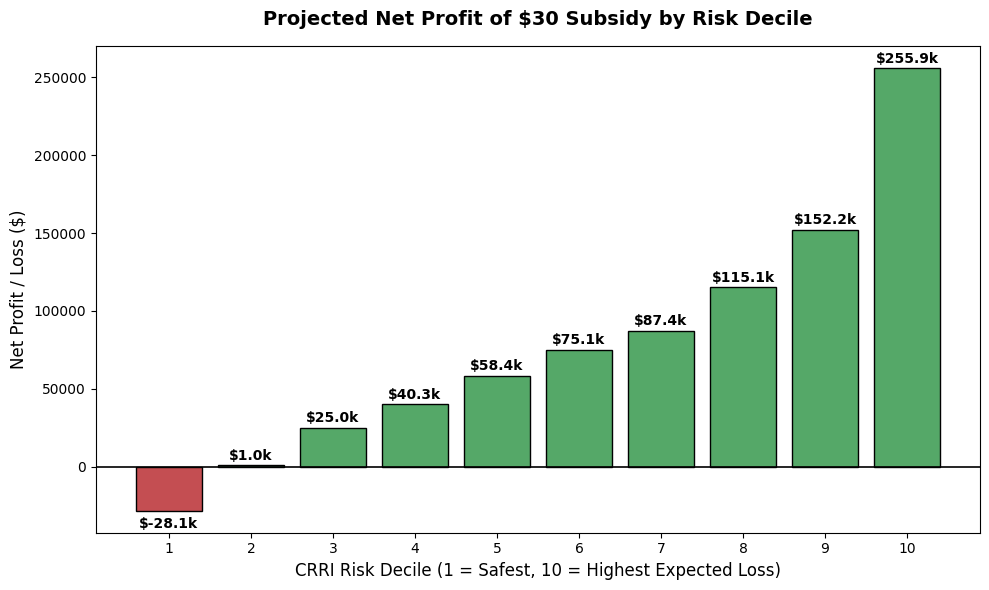

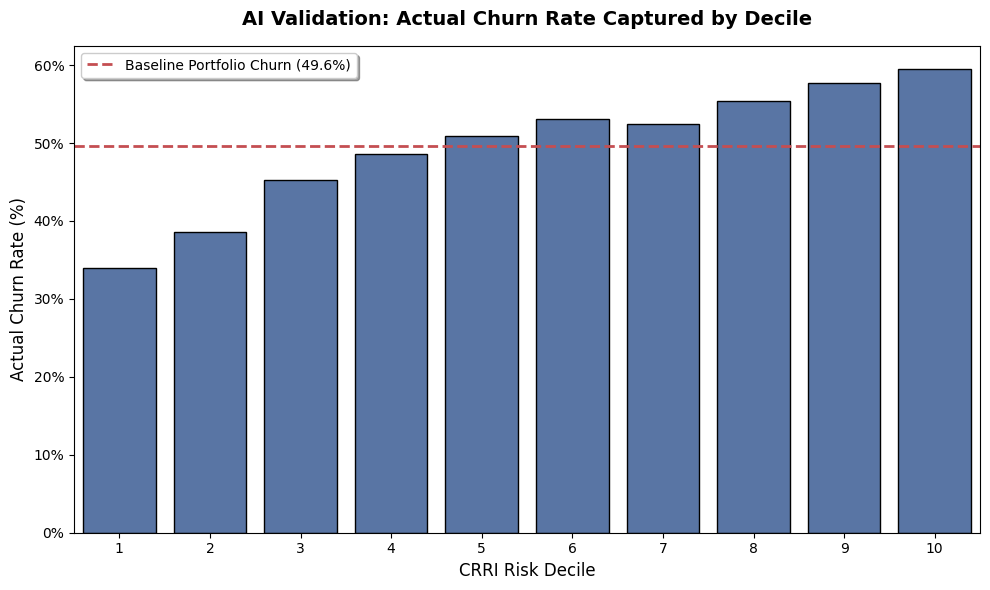

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mtick

print("Generating Executive Slide Assets for CRRI Framework..")

# PLOT 1: THE BUSINESS DECISION (Net Profit by Decile)
# This proves to executives that targeting everyone loses money,
# but targeting Deciles 8, 9, and 10 generates massive ROI.
plt.figure(figsize=(10, 6))

# Color code: Green for profit, Red for loss
colors = ['#C44E52' if x < 0 else '#55A868' for x in decile_analysis['net_profit']]

#the bar chart
bars = plt.bar(decile_analysis['CRRI_Decile'], decile_analysis['net_profit'], color=colors, edgecolor='black')

# data labels onto the bars for slide readability
for bar in bars:
    yval = bar.get_height()
    # Adjust text position based on positive/negative value
    label_y = yval + (1500 if yval > 0 else -4000)
    plt.text(bar.get_x() + bar.get_width()/2, label_y, f'${yval/1000:,.1f}k',
             ha='center', va='bottom' if yval > 0 else 'top', fontweight='bold', fontsize=10)

plt.title('Projected Net Profit of $30 Subsidy by Risk Decile', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('CRRI Risk Decile (1 = Safest, 10 = Highest Expected Loss)', fontsize=12)
plt.ylabel('Net Profit / Loss ($)', fontsize=12)
plt.axhline(0, color='black', linewidth=1.2)
plt.xticks(range(1, 11))
plt.tight_layout()
plt.savefig('slide_11_decile_profit.png', dpi=300, bbox_inches='tight')
plt.show()

# PLOT 2: THE MODEL VALIDATION (Churn Lift Chart)
# This proves the machine learning actually works. It shows that
# the people the model ranks as "High Risk" actually do churn at massive rates.

plt.figure(figsize=(10, 6))

# Create the bar chart
sns.barplot(data=decile_analysis, x='CRRI_Decile', y='actual_churn_rate', color='#4C72B0', edgecolor='black')

# Add a horizontal line showing the baseline churn rate for comparison
baseline_churn = crri_df['actual_churn'].mean()
plt.axhline(baseline_churn, color='#C44E52', linestyle='--', linewidth=2,
            label=f'Baseline Portfolio Churn ({baseline_churn:.1%})')

# Format y-axis as percentages
plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

plt.title('AI Validation: Actual Churn Rate Captured by Decile', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('CRRI Risk Decile', fontsize=12)
plt.ylabel('Actual Churn Rate (%)', fontsize=12)
plt.legend(loc='upper left', frameon=True, shadow=True)

plt.tight_layout()
plt.savefig('slide_10_churn_lift.png', dpi=300, bbox_inches='tight')
plt.show()

#Section 16: ROC Curve

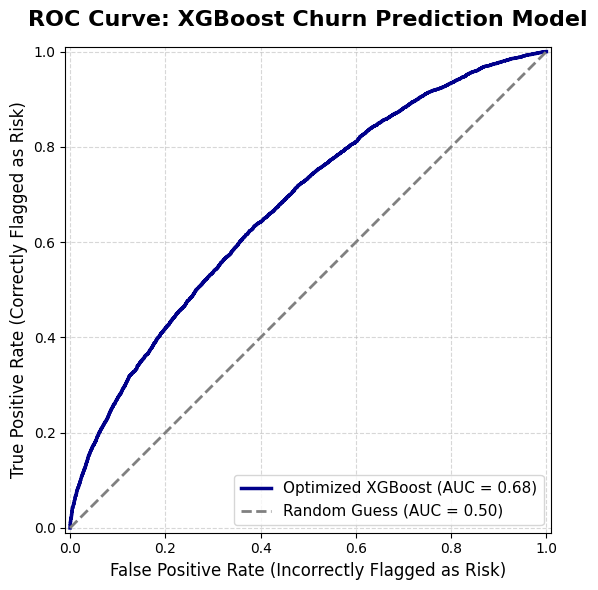

In [22]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

# Set up the plot for slide
plt.figure(figsize=(8, 6))
ax = plt.gca()

# the ROC Curve for the XGBoost model
RocCurveDisplay.from_estimator(
    best_xgb,
    X_test,
    y_test,
    ax=ax,
    name='Optimized XGBoost',
    color='darkblue',
    linewidth=2.5
)

plt.plot([0, 1], [0, 1], linestyle='--', lw=2, color='gray', label='Random Guess (AUC = 0.50)')

# Format the chart
plt.title('ROC Curve: XGBoost Churn Prediction Model', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('False Positive Rate (Incorrectly Flagged as Risk)', fontsize=12)
plt.ylabel('True Positive Rate (Correctly Flagged as Risk)', fontsize=12)
plt.legend(loc="lower right", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()

# Save the visual
plt.savefig('roc_curve_xgboost.png', dpi=300, bbox_inches='tight')

# Display the plot
plt.show()